# Vogel oder Park: Was hat das Modell gelernt?

Das erste Notebook hatte 39 von 40 richtig. Das sagt nicht, warum. Vögel und Parks stammen aus verschiedenen Quellen: Vogelfotos sind meist Nahaufnahmen, Parkfotos Weitwinkel. Das Modell könnte also auch „Nahaufnahme gegen Weitwinkel“ gelernt haben, und die Accuracy würde genauso gut aussehen.

Drei Tests:

1. Worauf schaut das Modell?
2. Was passiert, wenn wir den Vogel verdecken?
3. Was passiert, wenn der Vogel klein wird und der Park nah?

## Das Modell aus dem ersten Notebook

Derselbe Split, dasselbe Modell, dieselben drei Epochen, ohne Erklärungen.

In [ ]:
# Nur in Colab: Hilfsdateien und Daten aus dem Repo holen. Lokal tut die Zelle nichts.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    repo = "/content/ki-workshop-handson"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/dprinz/ki-workshop-handson.git", repo], check=True)
    os.chdir(f"{repo}/01-vogel-oder-park")

In [1]:
import torch
from PIL import Image
from sklearn.model_selection import train_test_split
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import ImageFolder
from torchvision.models import ResNet18_Weights, resnet18

from helfer import zeige_bilder, zeige_karten

gewichte = ResNet18_Weights.DEFAULT
aufbereiten = gewichte.transforms()
bilder = ImageFolder("daten", transform=aufbereiten)
idx_training, idx_validierung = train_test_split(
    range(len(bilder)), test_size=0.2, stratify=bilder.targets, random_state=42
)
training = DataLoader(Subset(bilder, idx_training), batch_size=16, shuffle=True)

geraet = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
torch.manual_seed(42)
modell = resnet18(weights=gewichte)
for parameter in modell.parameters():
    parameter.requires_grad = False
modell.fc = nn.Linear(modell.fc.in_features, 2)
modell = modell.to(geraet).eval()

optimierer = torch.optim.Adam(modell.fc.parameters(), lr=0.001)
for epoche in range(3):
    for eingabe, label in training:
        loss = nn.functional.cross_entropy(modell(eingabe.to(geraet)), label.to(geraet))
        optimierer.zero_grad()
        loss.backward()
        optimierer.step()

VOGEL = bilder.class_to_idx["vogel"]
voegel = [bilder.samples[i][0] for i in idx_validierung if bilder.targets[i] == VOGEL]
parks = [bilder.samples[i][0] for i in idx_validierung if bilder.targets[i] != VOGEL]


def p_vogel(bild):
    """Wahrscheinlichkeit für Vogel, für ein PIL-Bild."""
    with torch.no_grad():
        return torch.softmax(modell(aufbereiten(bild).unsqueeze(0).to(geraet)), dim=1)[0, VOGEL].item()


oeffne = lambda pfad: Image.open(pfad).convert("RGB")
print(f"{len(voegel)} Vögel und {len(parks)} Parks aus der Validierung, im Training nie gesehen")

20 Vögel und 20 Parks aus der Validierung, im Training nie gesehen


## 1. Worauf schaut das Modell?

Die letzte Convolutional Layer liefert 512 Features für jedes Feld eines Rasters von 7 × 7. Unsere neue Schicht bildet daraus den Mittelwert und gewichtet ihn. Rechnet man das Gewichten pro Feld statt über den Mittelwert, sieht man, welche Stelle wie stark für Vogel oder Park spricht (Class Activation Map, Zhou et al. 2016).

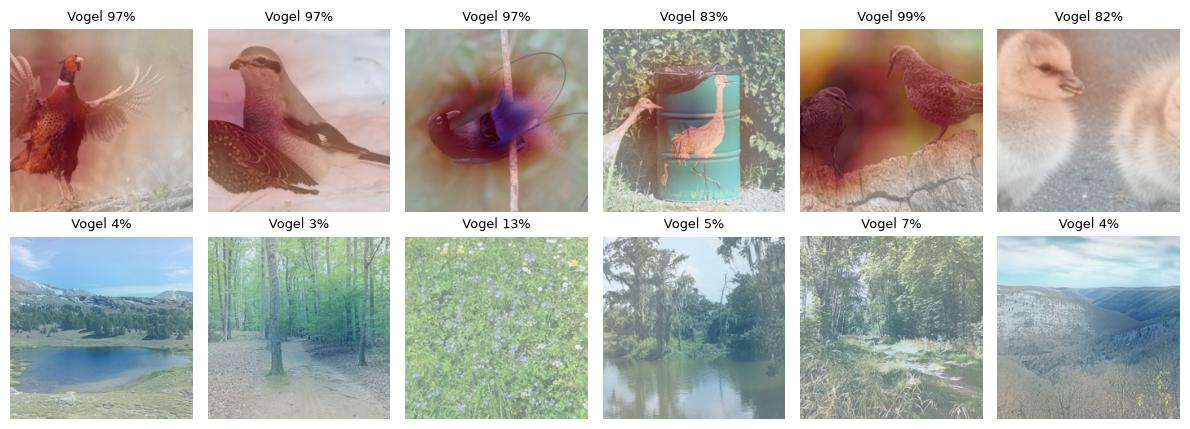

In [2]:
def karte(bild):
    """Pro Feld des Rasters: Stimme für Vogel minus Stimme für Park, hochskaliert auf 224 × 224."""
    ablage = {}
    haken = modell.layer4.register_forward_hook(lambda _m, _e, ausgabe: ablage.update(merkmale=ausgabe))
    with torch.no_grad():
        modell(aufbereiten(bild).unsqueeze(0).to(geraet))
    haken.remove()
    gewichtung = modell.fc.weight[VOGEL] - modell.fc.weight[1 - VOGEL]
    raster = torch.einsum("c,bchw->bhw", gewichtung, ablage["merkmale"]).unsqueeze(1)
    return F.interpolate(raster, size=(224, 224), mode="bilinear", align_corners=False)[0, 0].detach().cpu().numpy()


def ausschnitt(bild):
    """Das Bild, wie es das Modell sieht: kurze Kante 256, Mitte 224."""
    breite, hoehe = bild.size
    faktor = 256 / min(breite, hoehe)
    bild = bild.resize((round(breite * faktor), round(hoehe * faktor)))
    links, oben = (bild.width - 224) // 2, (bild.height - 224) // 2
    return bild.crop((links, oben, links + 224, oben + 224))


auswahl = voegel[:6] + parks[:6]
fotos = [oeffne(p) for p in auswahl]
zeige_karten([ausschnitt(f) for f in fotos], [karte(f) for f in fotos], [f"Vogel {p_vogel(f):.0%}" for f in fotos])

Bei den Vögeln liegt das Rot meist auf dem Tier, aber nicht nur: Beim Paar auf dem Baumstumpf zählt auch der unscharfe Hintergrund neben den Tieren. Bei den Parks verteilt sich die Stimme flach über das Bild. Die Karte zeigt, wohin das Modell schaut. Was es dort sieht, zeigt sie nicht.

## 2. Was passiert, wenn wir den Vogel verdecken?

Die Karte zeigt, wohin das Modell schaut, nicht, ob es darauf angewiesen ist. Also verdecken wir bei jedem Vogelfoto die Stelle, die am stärksten für Vogel spricht, mit einem grauen Quadrat. Bleibt die Antwort Vogel, reicht dem Modell der Rest des Bildes.

25% der Kantenlänge verdeckt: 18 von 20 bleiben Vogel, mittlere Wahrscheinlichkeit 81%


50% der Kantenlänge verdeckt: 14 von 20 bleiben Vogel, mittlere Wahrscheinlichkeit 73%


75% der Kantenlänge verdeckt: 13 von 20 bleiben Vogel, mittlere Wahrscheinlichkeit 65%
unverdeckt: 19 von 20 Vogel, mittlere Wahrscheinlichkeit 88%


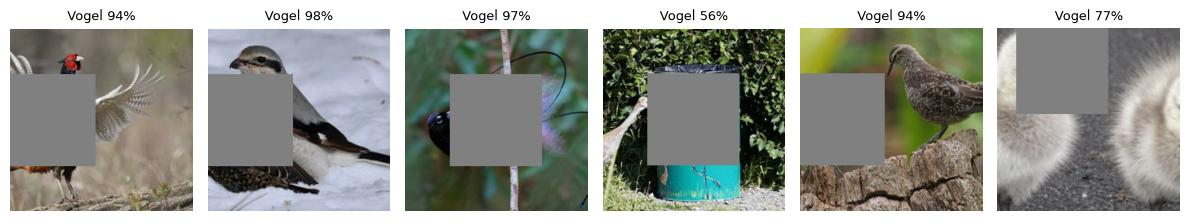

In [3]:
from PIL import ImageDraw, ImageFilter


def verdecke(bild, anteil):
    """Graues Quadrat auf die Stelle mit der stärksten Stimme für Vogel."""
    zeile, spalte = divmod(int(karte(bild).argmax()), 224)
    bild = ausschnitt(bild)
    halb = int(224 * anteil / 2)
    ImageDraw.Draw(bild).rectangle((spalte - halb, zeile - halb, spalte + halb, zeile + halb), fill=(128, 128, 128))
    return bild


vorher = [p_vogel(oeffne(p)) for p in voegel]
for anteil in (0.25, 0.5, 0.75):
    nachher = [p_vogel(verdecke(oeffne(p), anteil)) for p in voegel]
    bleibt = sum(n > 0.5 for n in nachher)
    print(f"{anteil:.0%} der Kantenlänge verdeckt: {bleibt} von {len(voegel)} bleiben Vogel, mittlere Wahrscheinlichkeit {sum(nachher) / len(nachher):.0%}")
print(f"unverdeckt: {sum(v > 0.5 for v in vorher)} von {len(voegel)} Vogel, mittlere Wahrscheinlichkeit {sum(vorher) / len(vorher):.0%}")

verdeckt = [verdecke(oeffne(p), 0.5) for p in voegel[:6]]
zeige_bilder(verdeckt, [f"Vogel {p_vogel(b):.0%}" for b in verdeckt])

Bei einem Quadrat von 75 % der Kantenlänge ist gut die Hälfte der Bildfläche weg, und 13 von 20 Bildern bleiben Vogel. Sichtbar bleiben dabei oft noch Kopf oder Flügel, der Test beweist also nicht, dass der Hintergrund allein reicht. Er zeigt nur, dass das Modell nicht an der einen Stelle hängt, die auf der Karte am stärksten leuchtet.

## 3. Was passiert, wenn der Vogel klein wird und der Park nah?

Jetzt direkt der Verdacht. Hat das Modell Nahaufnahme gegen Weitwinkel gelernt, müsste ein naher Ausschnitt aus einem Park nach Vogel aussehen und ein kleiner Vogel in einem Park nach Park.

Parks, immer näher:
  1-fach: 0 von 20 gelten als Vogel, Mittel 7%


  2-fach: 0 von 20 gelten als Vogel, Mittel 12%
  4-fach: 2 von 20 gelten als Vogel, Mittel 31%


  8-fach: 8 von 20 gelten als Vogel, Mittel 50%
Parks, immer unschärfer:


  Radius 2: 0 von 20 gelten als Vogel, Mittel 24%


  Radius 4: 6 von 20 gelten als Vogel, Mittel 45%


  Radius 8: 19 von 20 gelten als Vogel, Mittel 63%


  Radius 16: 20 von 20 gelten als Vogel, Mittel 69%
  einfarbig graue Fläche: Vogel 70%
Vögel, immer kleiner in einem Park:


  75.0% der Kante: 17 von 20 gelten als Vogel, Mittel 75%


  50.0% der Kante: 14 von 20 gelten als Vogel, Mittel 59%


  25.0% der Kante: 4 von 20 gelten als Vogel, Mittel 30%


  12.5% der Kante: 1 von 20 gelten als Vogel, Mittel 16%


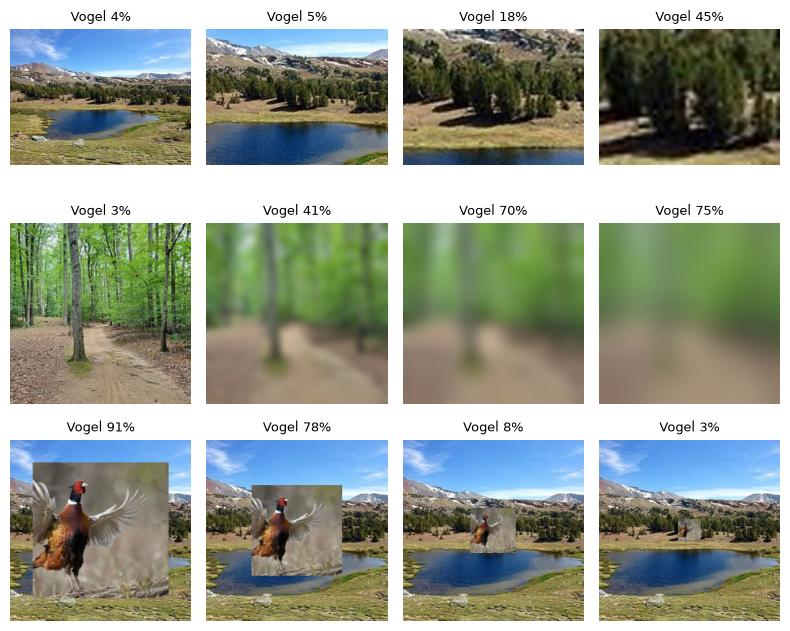

In [4]:
def zoome(bild, faktor):
    """Schneidet die Mitte aus und zieht sie auf die alte Grösse."""
    breite, hoehe = bild.size
    b, h = int(breite / faktor), int(hoehe / faktor)
    links, oben = (breite - b) // 2, (hoehe - h) // 2
    return bild.crop((links, oben, links + b, oben + h)).resize((breite, hoehe))


def setze_ein(vogel, park, anteil):
    """Setzt das Vogelfoto verkleinert in die Mitte eines Parkfotos."""
    park = ausschnitt(park)
    kante = int(224 * anteil)
    klein = ausschnitt(vogel).resize((kante, kante))
    park.paste(klein, ((224 - kante) // 2, (224 - kante) // 2))
    return park


print("Parks, immer näher:")
for faktor in (1, 2, 4, 8):
    werte = [p_vogel(zoome(oeffne(p), faktor)) for p in parks]
    print(f"  {faktor}-fach: {sum(w > 0.5 for w in werte)} von {len(parks)} gelten als Vogel, Mittel {sum(werte) / len(werte):.0%}")

print("Parks, immer unschärfer:")
for radius in (2, 4, 8, 16):
    werte = [p_vogel(ausschnitt(oeffne(p)).filter(ImageFilter.GaussianBlur(radius))) for p in parks]
    print(f"  Radius {radius}: {sum(w > 0.5 for w in werte)} von {len(parks)} gelten als Vogel, Mittel {sum(werte) / len(werte):.0%}")

print(f"  einfarbig graue Fläche: Vogel {p_vogel(Image.new('RGB', (224, 224), (128, 128, 128))):.0%}")

print("Vögel, immer kleiner in einem Park:")
paare = list(zip(voegel, parks))
for anteil in (0.75, 0.5, 0.25, 0.125):
    werte = [p_vogel(setze_ein(oeffne(v), oeffne(p), anteil)) for v, p in paare]
    print(f"  {anteil:.1%} der Kante: {sum(w > 0.5 for w in werte)} von {len(paare)} gelten als Vogel, Mittel {sum(werte) / len(werte):.0%}")

unscharf = [ausschnitt(oeffne(parks[1])).filter(ImageFilter.GaussianBlur(r)) for r in (0, 4, 8, 16)]
nah = [zoome(oeffne(parks[0]), f) for f in (1, 2, 4, 8)]
klein = [setze_ein(oeffne(voegel[0]), oeffne(parks[0]), a) for a in (0.75, 0.5, 0.25, 0.125)]
beispiele = nah + unscharf + klein
zeige_bilder(beispiele, [f"Vogel {p_vogel(b):.0%}" for b in beispiele], spalten=4)

Das Ergebnis stützt den Verdacht und geht darüber hinaus:

- **Näher heisst mehr Vogel:** Bei 8-facher Vergrösserung gelten 8 von 20 Parks als Vogel, ohne dass einer zu sehen ist.
- **Unschärfe reicht:** Bei Radius 8 gelten 19 von 20 Parks als Vogel. Vogelfotos haben oft einen unscharfen Hintergrund, Parkfotos nicht.
- **Grau ist Vogel:** Eine einfarbige Fläche gilt mit 70 % als Vogel. Fehlen die Park-Features, bleibt für das Modell nur die andere Klasse. Mit zwei Klassen muss es eine nennen.
- **Klein heisst weg:** Ein Vogel mit einem Achtel der Bildkante gilt fast nie als Vogel. Das liegt nicht nur am Modell, 28 Pixel sind wenig.

Das Modell erkennt tatsächlich Vögel, die Features aus ImageNet bringen das mit. Es hat aber auch mitgenommen, was in diesen Daten zufällig mit Vogel zusammenhängt. Das heisst Shortcut Learning (Geirhos et al. 2020) und ist mit Leakage verwandt: Die Validierung kommt aus denselben Quellen, hat dieselbe Schwäche und meldet trotzdem 39 von 40.

Mehr Epochen helfen dagegen nicht. Helfen würden Daten, in denen die Verknüpfung nicht gilt: Vögel und Parks aus derselben Quelle, Vögel in der Landschaft, Nahaufnahmen aus dem Park und eine dritte Klasse für alles andere.

Die Zahlen stammen aus je 20 Bildern und zeigen nur die Richtung.